#GOLD PRICE PREDICTION USING LSTM:

* DATASET: Gold_price_lstm_data.csv(300rows)
* TARGET: Gold_price(next day $ predict)
* MODEL: LSTM(Long Short-Term Memory)
* FEATURES: USD/INR, Crude Oil, Silver, inflation, interest Rate, Stock Index

STEP 1: INSTALL & IMPORT LIBRARIES:

In [ ]:
!pip install -q tensorflow pandas scikit-learn matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings("ignore")
print(" ✅ Libraries imported")

 ✅ Libraries imported


#✅ STEP 2: UPLOAD & LOAD DATASET:

In [ ]:
from google.colab import files
uploaded = files.upload() #gold_price_lstm_dataset.csv upload

Saving Gold_price_prediction_using_LSTM (1).ipynb to Gold_price_prediction_using_LSTM (1).ipynb


In [ ]:
df = pd.read_csv("/content/gold_price_lstm_dataset.csv")
df.head()

,Date,Gold_Price,USD_INR,Crude_Oil,Silver_Price,Inflation_Rate,Interest_Rate,Stock_Index,Demand_Index,Supply_Index,Global_Uncertainty
0,2021-01-01,46421.52,80.95,41.88,62425.79,4.34,6.95,48834.97,95.1,58.9,49.5
1,2021-01-02,45818.22,75.06,77.90,55716.47,4.19,6.60,42247.07,64.9,81.5,76.7
2,2021-01-03,45944.76,83.28,92.36,64186.76,3.93,7.83,31829.73,59.2,59.4,79.3
3,2021-01-04,46060.02,83.30,94.73,69478.16,8.84,5.51,42602.03,92.3,82.8,80.3
4,2021-01-05,45886.74,81.86,43.44,61153.25,4.74,4.32,26639.54,59.5,67.5,64.5


In [ ]:
print("shape:", df.shape)

shape: (300, 11)


In [ ]:
print("\nGold price Stats:")
print(df["Gold_Price"].describe().round(2))


Gold price Stats:
count      300.00
mean     46264.13
std       2164.42
min      43000.00
25%      44548.64
50%      45620.68
75%      48022.21
max      51197.45
Name: Gold_Price, dtype: float64


#STEP 3: PREPROCESSING:

In [ ]:
#Date drop
df.drop("Date", axis=1, inplace=True)

#MinMaxScaler _ o to 1 Scale
scaler = MinMaxScaler()
scaled = scaler.fit_transform(df)
scaled_df = pd.DataFrame(scaled, columns=df.columns)

print("✅ Scaling Done!")
print(f"Feature {list(df.columns)}")

✅ Scaling Done!
Feature ['Gold_Price', 'USD_INR', 'Crude_Oil', 'Silver_Price', 'Inflation_Rate', 'Interest_Rate', 'Stock_Index', 'Demand_Index', 'Supply_Index', 'Global_Uncertainty']


#✅ STEP 4: TIME-SERIES SEQUENCES:

In [ ]:
def create_sequences(data, target_col, seq_len=15):
  X,y = [],[]
  target_idx = list(data.columns).index(target_col)
  vals = data.values
  for i in range(len(vals)- seq_len):
      X.append(vals[i:i+seq_len])
      y.append(vals[i+seq_len][target_idx])

  return np.array(X), np.array(y)

SEQ_LEN = 15 #16th day prediction by looking at last 15 days
X, y = create_sequences(scaled_df, "Gold_Price", SEQ_LEN)

split = int(len(X)*0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")


X_train: (228, 15, 10)
X_test:  (57, 15, 10)


#STEP 5: BIDIRECTIONAL LSTM MODEL BUILD:

In [ ]:
model = Sequential([
    Bidirectional(LSTM(128, return_sequences=True),
                  input_shape=(SEQ_LEN, X.shape[2])),

    Dropout(0.2),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32, return_sequences=False),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)

])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 15, 256)        │       142,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 15, 64)         │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 237,473 (927.63 KB)

 Trainable params: 237,473 (927.63 KB)

 Non-trainable params: 0 (0.00 B)

#STEP 6: MODEL TRAIN:

In [ ]:
early_stop = EarlyStopping(monitor="val_loss", patience=15,
                           restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                              patience=7, min_lr=1e-6)

history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)
print("\n✅ Training Done!")

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 112ms/step - loss: 0.0371 - mae: 0.1579 - val_loss: 0.1014 - val_mae: 0.2889 - learning_rate: 0.0010
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0201 - mae: 0.1149 - val_loss: 0.0728 - val_mae: 0.2474 - learning_rate: 0.0010
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0143 - mae: 0.0929 - val_loss: 0.0507 - val_mae: 0.2090 - learning_rate: 0.0010
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0074 - mae: 0.0704 - val_loss: 0.0440 - val_mae: 0.1956 - learning_rate: 0.0010
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0063 - mae: 0.0625 - val_loss: 0.0461 - val_mae: 0.2016 - learning_rate: 0.0010
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0067 - mae: 0.0628 - val_loss: 0.0481 - val_mae: 0.2070 - learning_rate: 0.0010
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0080 - mae: 0.0684 - val_loss: 0.0137 - val_mae: 0.1023 - learning_rate: 0.0010
Epoch

#✅ STEP 7: EVALUATE & INVERSE SCALE:

In [ ]:
y_pred_scaled = model.predict(X_test).flatten()

#Inverse scale - back to $ values
gold_idx = list(df.columns).index("Gold_Price")
gold_min = scaler.data_min_[gold_idx]
gold_max = scaler.data_max_[gold_idx]

y_test_orig = y_test * (gold_max - gold_min) + gold_min
y_pred_orig= y_pred_scaled * (gold_max - gold_min) + gold_min

mae = mean_absolute_error(y_test_orig, y_pred_orig)
rmse = np.sqrt(mean_squared_error(y_test_orig, y_pred_orig))
r2 = r2_score(y_test_orig, y_pred_orig)

print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R2: {r2:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
MAE: 1,484.72
RMSE: 1,554.19
R2: -3.4682


#STEP 8: CHARTS - 4 VISUALIZATIONS:

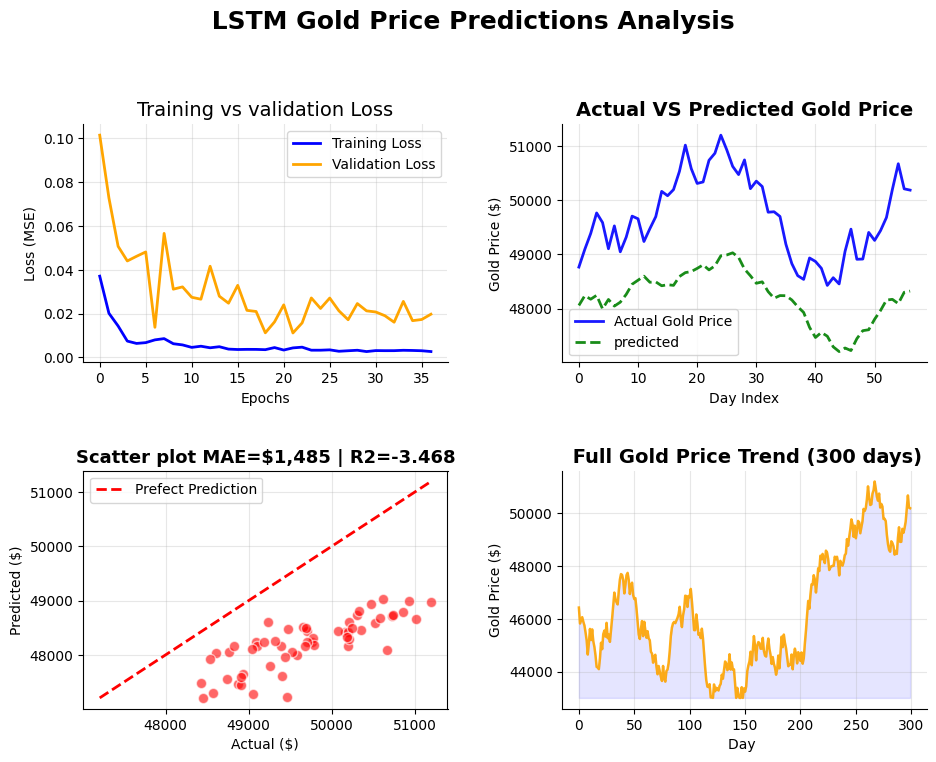

✅ Charts Saved


In [ ]:
fig, axes = plt.subplots(2,2, figsize=(10,8))
fig.suptitle(" LSTM Gold Price Predictions Analysis",
             fontsize=18, fontweight="bold")
fig.patch.set_facecolor("white")

# chart 1: Training Loss
ax1 = axes[0,0]
ax1.plot(history.history["loss"],  color="blue", lw=2, label="Training Loss")
ax1.plot(history.history["val_loss"], color="orange",lw=2, label="Validation Loss")
ax1.set_title("Training vs validation Loss", fontsize=14)
ax1.set_xlabel("Epochs"); ax1.set_ylabel("Loss (MSE)")
ax1.legend(); ax1.grid(alpha=0.3)
ax1.set_facecolor("white")
ax1.spines[["top", "right"]].set_visible(False)

# charts 2: Actual VS Predicted Line

ax2 = axes[0,1]
ax2.plot(y_test_orig, color = "blue", lw=2, label="Actual Gold Price", alpha=0.9)
ax2.plot(y_pred_orig, color="green",lw=2, linestyle="--", label="predicted", alpha=0.9 )
ax2.set_title("Actual VS Predicted Gold Price", fontsize=14, fontweight="bold")
ax2.set_xlabel("Day Index"); ax2.set_ylabel("Gold Price ($)")
ax2.legend(); ax2.grid(alpha=0.3)
ax2.set_facecolor("white")
ax2.spines[["top", "right"]].set_visible(False)

# charts 3: Scatter
ax3 = axes[1,0]
ax3.scatter(y_test_orig, y_pred_orig, color="red",
            alpha=0.6, s=55,edgecolor="white", zorder=3)
mn = min(y_test_orig.min(), y_pred_orig.min())
mx = max(y_test_orig.max(), y_pred_orig.max())
ax3.plot([mn,mx], [mn,mx], "r--", lw=2, label="Prefect Prediction")
ax3.set_title(f"Scatter plot MAE=${mae:,.0f} | R2={r2:.3f}",
              fontsize=13, fontweight="bold")
ax3.set_xlabel("Actual ($)"); ax3.set_ylabel("Predicted ($)")
ax3.legend(); ax3.grid(alpha=0.3, zorder=0)

# chart 4 full Gold Price Trend
orig = pd.read_csv("gold_price_lstm_dataset.csv")
ax4 = axes[1,1]
ax4.plot(orig.index, orig["Gold_Price"], color="orange", lw=1.8, alpha=0.9)
ax4.fill_between(orig.index, orig["Gold_Price"],
                 orig["Gold_Price"].min(), alpha=0.1, color="blue")
ax4.set_title(" Full Gold Price Trend (300 days)", fontsize=14, fontweight="bold")
ax4.set_xlabel("Day "); ax4.set_ylabel("Gold Price ($)")
ax4.grid(alpha=0.3)
ax4.set_facecolor("white")
ax4.spines[["top", "right"]].set_visible(False)

plt.tight_layout(pad=3.0)
plt.savefig("gold_istm_charts.png",dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print("✅ Charts Saved")

#STEP 9: NEXT DAY GOLD PRICE PREDICT:

In [ ]:
last_seq = scaled_df.values[-SEQ_LEN:].reshape(1, SEQ_LEN, scaled_df.shape[1])
next_scaled = model.predict(last_seq)[0][0]
next_price = next_scaled * (gold_max - gold_min) + gold_min

last_price = orig["Gold_Price"].iloc[-1]
change     = next_price - last_price
pct        = (change / last_price) * 100

print(f"✅ Last Known Price  :  $ {last_price:,.2f}")
print(f"✅ Predicted Tomorrow:  $ {next_price:,.2f}")
print(f"✅ Change            :  $ {change:+,.2f} ({pct:+.2f}%)")

if change > 0:
  print("✅ TREND BULLISH -  GOLD PRICE INCREASE")
else:
  print("✅ TREND: BEARISH - GOLD PRICE DECREASE")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
✅ Last Known Price  :  $ 50,184.15
✅ Predicted Tomorrow:  $ 48,262.18
✅ Change            :  $ -1,921.97 (-3.83%)
✅ TREND: BEARISH - GOLD PRICE DECREASE
